# Retail Sales Analysis

**Tools:** Python · pandas · matplotlib · seaborn · Jupyter

## Project overview
This project analyses 500 retail orders to answer practical business questions:

1. How much revenue and profit does the business *actually realise* once cancelled and returned orders are removed?
2. Which categories, channels, customer segments and cities drive that revenue?
3. Where is revenue being lost to returns and cancellations?
4. How does revenue change month to month, and how loyal are customers?

## Dataset
| Item | Detail |
|---|---|
| File | `retail_sales_raw_dataset.csv` |
| Rows / columns | 503 raw rows, 16 columns |
| Period | 2025 |
| Currency | Not stated in the source file; amounts are shown as plain numbers |
| Limitations | Small sample (500 orders). Cost is an *estimate* (`estimated_cost_raw`), so profit is estimated too. |

## Definitions used throughout
- **Gross order value**: value of *all* orders, including cancelled and returned ones.
- **Net revenue**: value of **Delivered** orders only. This is the headline revenue figure.
- **Return rate** = Returned ÷ (Delivered + Returned). **Cancellation rate** = Cancelled ÷ all orders.
- **Estimated profit** = net revenue − estimated cost of Delivered orders.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

# One consistent theme for every chart
NAVY, TEAL, GOLD, GREY, RED = "#142D4E", "#20A39E", "#E6B655", "#64748B", "#C8553D"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.titlecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "grid.color": "#E8EDF2",
})

pd.options.display.float_format = "{:,.2f}".format
DATA_PATH = "retail_sales_raw_dataset.csv"

## 2. Load and inspect the raw data

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (503, 16)


,order_id,order_date,customer_id,customer_segment,city,product_id,product_name,category,quantity,unit_price,discount_pct,sales_channel,payment_method,order_status,revenue_raw,estimated_cost_raw
0,ORD-00001,2025-01-13,C1152,Small Business,Chattogram,P002,USB-C Hub,Electronics,2.00,34.50,0.00,Website,Card,Delivered,69.00,36.00
1,ORD-00002,2025-01-16,C1167,Corporate,Sylhet,P001,Wireless Mouse,Electronics,1.00,18.99,0.00,Website,Mobile Banking,Cancelled,18.99,9.20
2,ORD-00003,2025-08-03,C1179,Small Business,Rangpur,P009,Monitor Stand,Furniture,1.00,39.00,0.15,Website,Mobile Banking,Delivered,33.15,20.00
3,ORD-00004,2025-05-23,C1092,Small Business,Dhaka,P006,Mechanical Keyboard,Electronics,1.00,69.99,0.05,Retail Store,Card,Delivered,66.49,39.00
4,ORD-00005,2025-05-16,C1021,Corporate,Sylhet,P010,Laptop Sleeve,Accessories,3.00,22.00,0.20,Website,Bank Transfer,Delivered,52.80,30.00


<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            503 non-null    str    
 1   order_date          503 non-null    str    
 2   customer_id         503 non-null    str    
 3   customer_segment    503 non-null    str    
 4   city                500 non-null    str    
 5   product_id          503 non-null    str    
 6   product_name        503 non-null    str    
 7   category            503 non-null    str    
 8   quantity            500 non-null    float64
 9   unit_price          500 non-null    float64
 10  discount_pct        499 non-null    float64
 11  sales_channel       503 non-null    str    
 12  payment_method      499 non-null    str    
 13  order_status        503 non-null    str    
 14  revenue_raw         503 non-null    float64
 15  estimated_cost_raw  503 non-null    float64
dtypes: float64(5), str(

## 3. Data quality audit
Before changing anything, record what is wrong with the raw data.

In [3]:
audit = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
display(audit[audit["missing"] > 0])

print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated order IDs  :", df["order_id"].duplicated().sum())

TEXT_COLS = ["customer_segment", "city", "product_name", "category",
             "sales_channel", "payment_method", "order_status"]

print("\nDistinct spellings per text column, as stored:")
for col in TEXT_COLS:
    print(f"  {col:17s}", sorted(df[col].dropna().unique().tolist()))

print("\nOrder status counts as stored:")
display(df["order_status"].value_counts(dropna=False))

,missing,missing_%
city,3,0.60
quantity,3,0.60
unit_price,3,0.60
discount_pct,4,0.80
payment_method,4,0.80


Exact duplicate rows: 3
Repeated order IDs  : 3

Distinct spellings per text column, as stored:
  customer_segment  ['Consumer', 'Corporate', 'Small Business']
  city              ['Barishal', 'Chattogram', 'Dhaka', 'Khulna', 'Rajshahi', 'Rangpur', 'Sylhet', 'dhaka ']
  product_name      ['Ballpoint Pens', 'Desk Lamp', 'Laptop Sleeve', 'Mechanical Keyboard', 'Monitor Stand', 'Notebook Set', 'Office Chair', 'USB-C Hub', 'Water Bottle', 'Wireless Mouse']
  category          ['Accessories', 'Electronics', 'Furniture', 'Home Office', 'Lifestyle', 'Stationery', 'accessories', 'electronics', 'furniture']
  sales_channel     ['Marketplace', 'Mobile App', 'Retail Store', 'Website', 'Website ']
  payment_method    ['Bank Transfer', 'Card', 'Cash on Delivery', 'Mobile Banking']
  order_status      ['Cancelled', 'Delivered', 'Returned', 'delivered']

Order status counts as stored:


order_status
Delivered    313
Returned     100
Cancelled     86
delivered      4
Name: count, dtype: int64

## 4. Cleaning
Each step below states **what** was done and **why**.

| # | Problem | Action | Reason |
|---|---|---|---|
| 1 | Exact duplicate rows | Drop | Same order recorded twice would double-count revenue |
| 2 | Same label written differently (`furniture`/`Furniture`, `Website`/`Website `, `delivered`/`Delivered`) | Trim spaces and unify letter case in every text column | Otherwise one group is split in two and rates/totals become wrong |
| 3 | Missing `city` / `payment_method` | Label as `Unknown` | Keeps the order, avoids guessing |
| 4 | Missing `unit_price` | Fill from the product's fixed price | Every product has exactly one price in the data |
| 5 | Missing `quantity` / `discount_pct` | Recover from `revenue_raw` where it can be solved exactly | Uses information already in the row instead of guessing |

In [4]:
log = {}

# 1. Duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log["duplicate rows removed"] = before - len(df)

# 2. Standardise text fields: trim spaces, then map every spelling to its most common form
spelling_fixed = {}
for col in TEXT_COLS:
    cleaned = df[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = cleaned.str.lower()
    canonical = cleaned.groupby(key).agg(lambda x: x.value_counts().idxmax())
    new = key.map(canonical)
    spelling_fixed[col] = int((new.fillna("") != df[col].fillna("")).sum())
    df[col] = new.astype(object)
log["text values re-spelled"] = sum(spelling_fixed.values())

df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
log["unparseable dates"] = int(df["order_date"].isna().sum())

# 3. Categorical gaps
log["city set to Unknown"] = int(df["city"].isna().sum())
log["payment_method set to Unknown"] = int(df["payment_method"].isna().sum())
df["city"] = df["city"].fillna("Unknown")
df["payment_method"] = df["payment_method"].fillna("Unknown")

# 4. unit_price: each product has a single price
price_map = (df.dropna(subset=["unit_price"])
               .groupby("product_id")["unit_price"]
               .agg(lambda s: s.mode().iloc[0]))
m = df["unit_price"].isna()
df.loc[m, "unit_price"] = df.loc[m, "product_id"].map(price_map)
log["unit_price filled from product"] = int(m.sum())

# 5a. quantity: solve from revenue_raw, accept only if it comes out as a whole number
implied_qty = df["revenue_raw"] / (df["unit_price"] * (1 - df["discount_pct"]))
ok = (df["quantity"].isna() & df["discount_pct"].notna()
      & ((implied_qty - implied_qty.round()).abs() < 0.05) & (implied_qty.round() >= 1))
df.loc[ok, "quantity"] = implied_qty[ok].round()
log["quantity recovered"] = int(ok.sum())

# 5b. discount: solve from revenue_raw, snap to the discount levels that exist in the data
levels = np.sort(df["discount_pct"].dropna().unique())
implied_disc = 1 - df["revenue_raw"] / (df["quantity"] * df["unit_price"])
snapped = pd.Series(levels[np.abs(implied_disc.values[:, None] - levels).argmin(axis=1)], index=df.index)
ok = (df["discount_pct"].isna() & df["quantity"].notna()
      & ((implied_disc - snapped).abs() < 0.01))
df.loc[ok, "discount_pct"] = snapped[ok]
log["discount recovered"] = int(ok.sum())

log["rows still missing quantity or discount"] = int(df[["quantity", "discount_pct"]].isna().any(axis=1).sum())

pd.Series(log, name="count").to_frame()

,count
duplicate rows removed,3
text values re-spelled,14
unparseable dates,0
city set to Unknown,3
payment_method set to Unknown,4
unit_price filled from product,3
quantity recovered,3
discount recovered,4
rows still missing quantity or discount,0


## 5. Validation: does the calculated revenue match the recorded revenue?
Revenue is recomputed as `quantity × unit_price × (1 − discount)` and compared with `revenue_raw`.
This is checked **once**, and a single definition of revenue is used from here on.

In [5]:
df["revenue_calc"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"])

comparable = df["revenue_calc"].notna()
matches = np.isclose(df.loc[comparable, "revenue_calc"], df.loc[comparable, "revenue_raw"], atol=0.02)
print(f"Rows where calculated revenue equals revenue_raw: {matches.mean():.1%} of {comparable.sum()} comparable rows")

# Single definition of revenue: calculated value, falling back to the recorded value only if a field is still missing
df["revenue"] = df["revenue_calc"].fillna(df["revenue_raw"])
df["estimated_cost"] = df["estimated_cost_raw"]
df["estimated_profit"] = df["revenue"] - df["estimated_cost"]
df["month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

# Sanity checks
assert df["order_id"].is_unique
assert (df["quantity"].dropna() > 0).all() and (df["unit_price"] > 0).all()
assert df["discount_pct"].dropna().between(0, 1).all()
print("Validation checks passed. Final shape:", df.shape)

print("\nDistinct values after cleaning:")
for col in ["category", "sales_channel", "order_status", "customer_segment", "city"]:
    print(f"  {col:17s}", sorted(df[col].dropna().unique().tolist()))

Rows where calculated revenue equals revenue_raw: 100.0% of 500 comparable rows
Validation checks passed. Final shape: (500, 21)

Distinct values after cleaning:
  category          ['Accessories', 'Electronics', 'Furniture', 'Home Office', 'Lifestyle', 'Stationery']
  sales_channel     ['Marketplace', 'Mobile App', 'Retail Store', 'Website']
  order_status      ['Cancelled', 'Delivered', 'Returned']
  customer_segment  ['Consumer', 'Corporate', 'Small Business']
  city              ['Barishal', 'Chattogram', 'Dhaka', 'Khulna', 'Rajshahi', 'Rangpur', 'Sylhet', 'Unknown']


In [6]:
df.to_csv("retail_sales_cleaned.csv", index=False)
print("Saved retail_sales_cleaned.csv")

Saved retail_sales_cleaned.csv


## 6. Headline numbers
Cancelled and returned orders are separated from **Delivered** orders so that revenue reflects money the business actually kept.

In [7]:
delivered = df[df["order_status"] == "Delivered"]
n_all = len(df)
n_del = len(delivered)
n_ret = (df["order_status"] == "Returned").sum()
n_can = (df["order_status"] == "Cancelled").sum()

gross_value = df["revenue"].sum()
net_revenue = delivered["revenue"].sum()
lost_value = gross_value - net_revenue
net_profit = delivered["estimated_profit"].sum()
margin = net_profit / net_revenue
aov = net_revenue / n_del
return_rate = n_ret / (n_del + n_ret)
cancel_rate = n_can / n_all

orders_per_customer = delivered.groupby("customer_id")["order_id"].nunique()
repeat_rate = (orders_per_customer > 1).mean()

kpis = pd.Series({
    "Total orders placed": f"{n_all:,}",
    "Delivered orders": f"{n_del:,}",
    "Gross order value (all orders)": f"{gross_value:,.2f}",
    "Net revenue (Delivered only)": f"{net_revenue:,.2f}",
    "Value lost to returns/cancellations": f"{lost_value:,.2f} ({lost_value / gross_value:.1%})",
    "Estimated profit (Delivered)": f"{net_profit:,.2f}",
    "Estimated profit margin": f"{margin:.1%}",
    "Average order value (Delivered)": f"{aov:,.2f}",
    "Return rate": f"{return_rate:.1%}",
    "Cancellation rate": f"{cancel_rate:.1%}",
    "Unique customers (Delivered)": f"{delivered['customer_id'].nunique():,}",
    "Repeat customers (2+ delivered orders)": f"{repeat_rate:.1%}",
}, name="Value").to_frame()
kpis

,Value
Total orders placed,500
Delivered orders,315
Gross order value (all orders),"35,408.37"
Net revenue (Delivered only),"21,310.28"
Value lost to returns/cancellations,"14,098.08 (39.8%)"
Estimated profit (Delivered),"8,469.78"
Estimated profit margin,39.7%
Average order value (Delivered),67.65
Return rate,24.1%
Cancellation rate,17.0%


## 7. Order outcomes

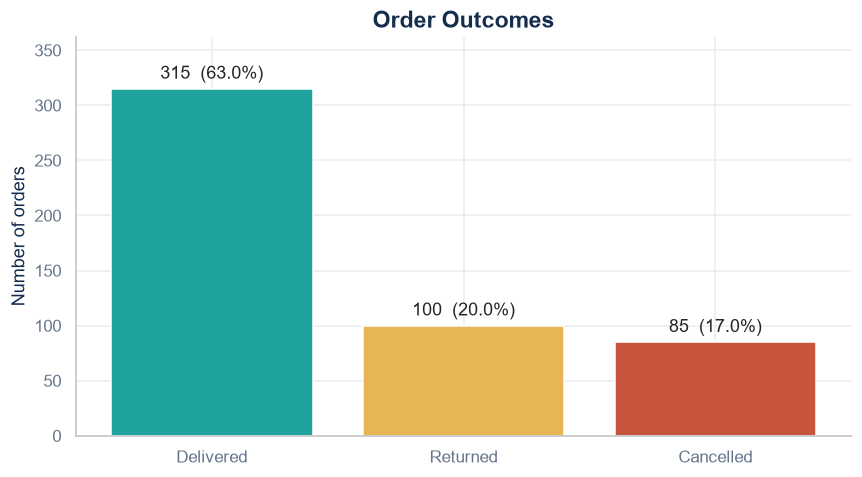

In [8]:
status = df["order_status"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"Delivered": TEAL, "Returned": GOLD, "Cancelled": RED}
bars = ax.bar(status.index, status.values, color=[colors.get(s, GREY) for s in status.index])
ax.bar_label(bars, labels=[f"{v}  ({v / n_all:.1%})" for v in status.values], padding=4)
ax.set_title("Order Outcomes")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, status.max() * 1.15)
plt.tight_layout()
plt.show()

## 8. Revenue and profit by category

,revenue,estimated_profit,margin,share
category,,,,
Furniture,"10,243.00","3,535.00",34.5%,48.1%
Electronics,"6,760.58","2,698.18",39.9%,31.7%
Home Office,"1,831.95",787.95,43.0%,8.6%
Lifestyle,991.50,601.00,60.6%,4.7%
Accessories,856.90,436.90,51.0%,4.0%
Stationery,626.36,410.75,65.6%,2.9%


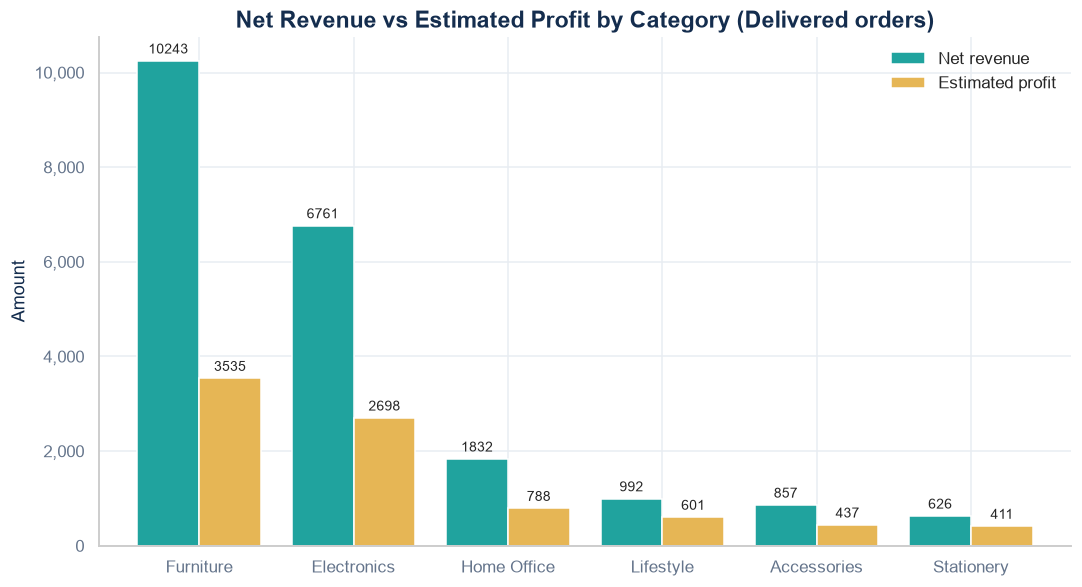

In [9]:
cat = (delivered.groupby("category")[["revenue", "estimated_profit"]].sum()
                .assign(margin=lambda d: d["estimated_profit"] / d["revenue"],
                        share=lambda d: d["revenue"] / d["revenue"].sum())
                .sort_values("revenue", ascending=False))
display(cat.style.format({"revenue": "{:,.2f}", "estimated_profit": "{:,.2f}",
                          "margin": "{:.1%}", "share": "{:.1%}"}))

ax = cat[["revenue", "estimated_profit"]].plot(kind="bar", color=[TEAL, GOLD], width=0.8, figsize=(10, 5.5))
ax.set_title("Net Revenue vs Estimated Profit by Category (Delivered orders)")
ax.set_xlabel("")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=0)
ax.legend(["Net revenue", "Estimated profit"], frameon=False)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", padding=3, fontsize=9)
plt.tight_layout()
plt.show()

## 9. Product performance

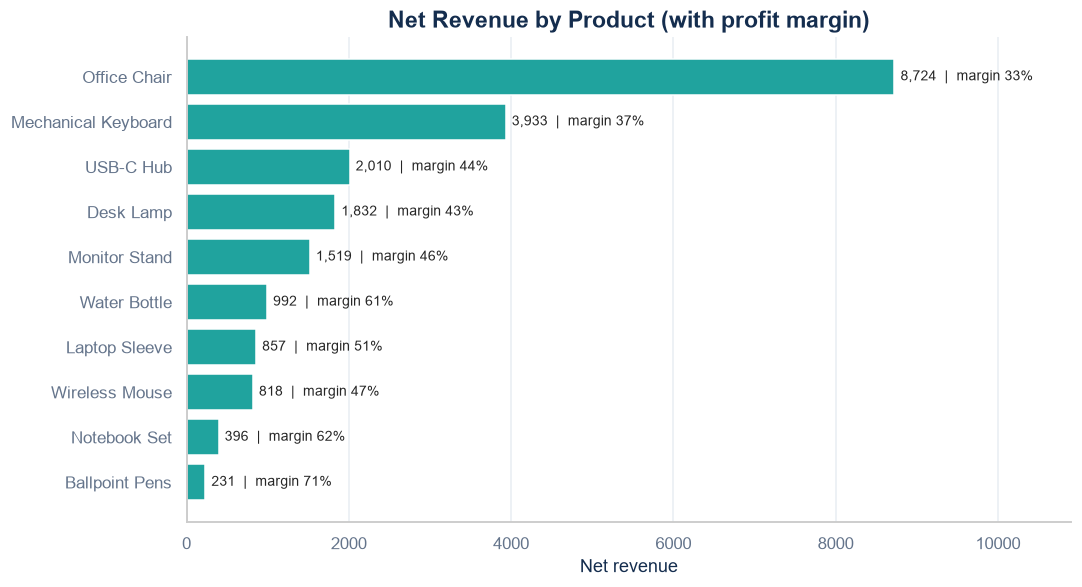

In [10]:
prod = (delivered.groupby("product_name")
                 .agg(units=("quantity", "sum"), revenue=("revenue", "sum"), profit=("estimated_profit", "sum"))
                 .assign(margin=lambda d: d["profit"] / d["revenue"])
                 .sort_values("revenue", ascending=True))

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(prod.index, prod["revenue"], color=TEAL)
ax.bar_label(bars, labels=[f"{r:,.0f}  |  margin {m:.0%}" for r, m in zip(prod["revenue"], prod["margin"])], padding=4, fontsize=9)
ax.set_title("Net Revenue by Product (with profit margin)")
ax.set_xlabel("Net revenue")
ax.set_xlim(0, prod["revenue"].max() * 1.25)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 10. Sales channel, customer segment and city

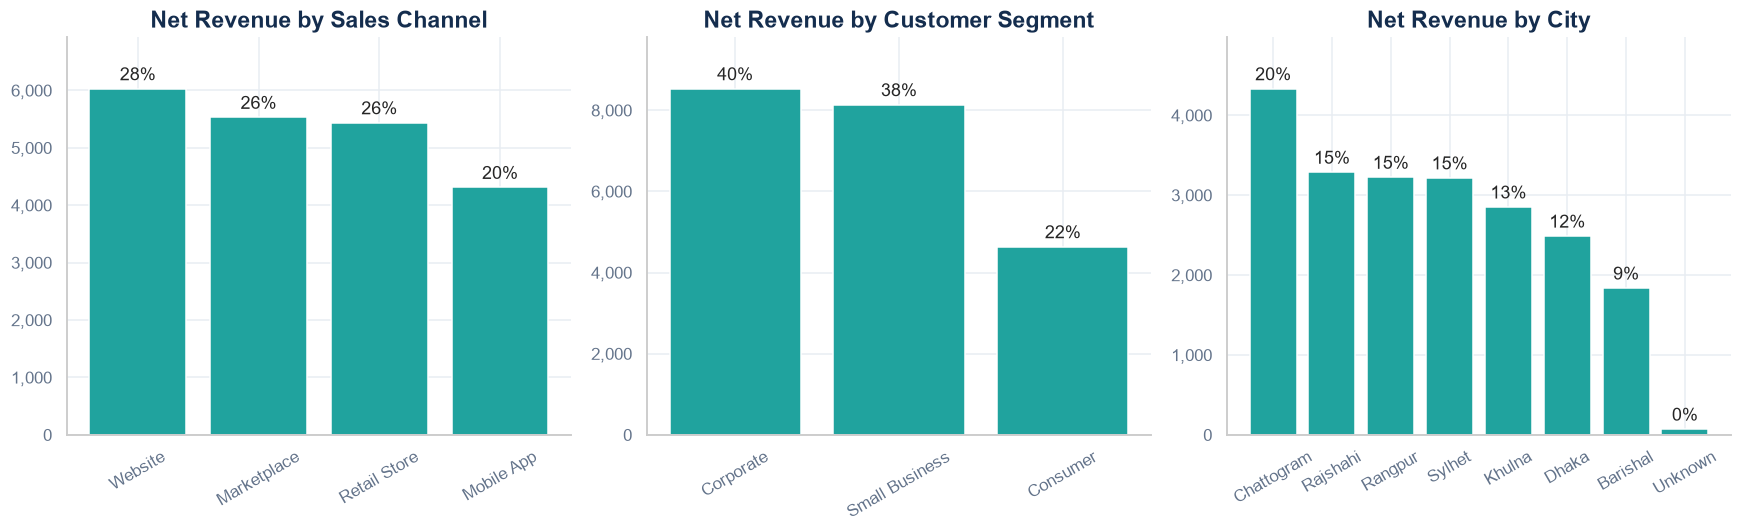

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, title in zip(axes,
                          ["sales_channel", "customer_segment", "city"],
                          ["Sales Channel", "Customer Segment", "City"]):
    s = delivered.groupby(col)["revenue"].sum().sort_values(ascending=False)
    bars = ax.bar(s.index, s.values, color=TEAL)
    ax.bar_label(bars, labels=[f"{v / s.sum():.0%}" for v in s.values], padding=3)
    ax.set_title(f"Net Revenue by {title}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.set_ylim(0, s.max() * 1.15)

plt.tight_layout()
plt.show()

## 11. Where revenue is lost: returns and cancellations

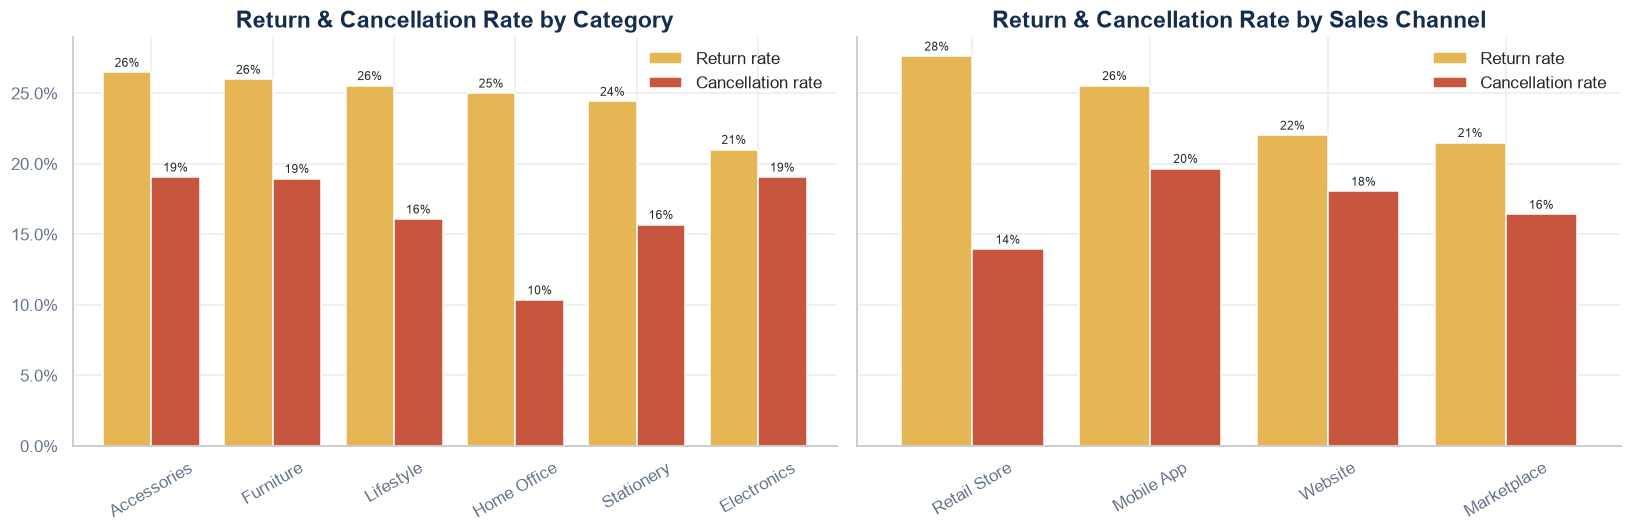

,return_rate,cancel_rate,orders
product_name,,,
Ballpoint Pens,31.2%,12.7%,55
Office Chair,28.9%,16.7%,54
Wireless Mouse,27.3%,17.5%,40
Laptop Sleeve,26.5%,19.0%,42
Water Bottle,25.5%,16.1%,56
Desk Lamp,25.0%,10.3%,58
Monitor Stand,21.9%,22.0%,41
Mechanical Keyboard,20.5%,21.4%,56
USB-C Hub,16.7%,17.6%,51


In [12]:
def loss_rates(col):
    t = pd.crosstab(df[col], df["order_status"])
    out = pd.DataFrame({
        "return_rate": t.get("Returned", 0) / (t.get("Delivered", 0) + t.get("Returned", 0)),
        "cancel_rate": t.get("Cancelled", 0) / t.sum(axis=1),
        "orders": t.sum(axis=1),
    })
    return out

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, col, title in zip(axes, ["category", "sales_channel"], ["Category", "Sales Channel"]):
    r = loss_rates(col).sort_values("return_rate", ascending=False)
    r[["return_rate", "cancel_rate"]].plot(kind="bar", ax=ax, color=[GOLD, RED], width=0.8)
    ax.set_title(f"Return & Cancellation Rate by {title}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.legend(["Return rate", "Cancellation rate"], frameon=False)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v:.0%}" for v in c.datavalues], padding=2, fontsize=8)
plt.tight_layout()
plt.show()

display(loss_rates("product_name").sort_values("return_rate", ascending=False)
        .style.format({"return_rate": "{:.1%}", "cancel_rate": "{:.1%}"}))

## 12. Monthly trend

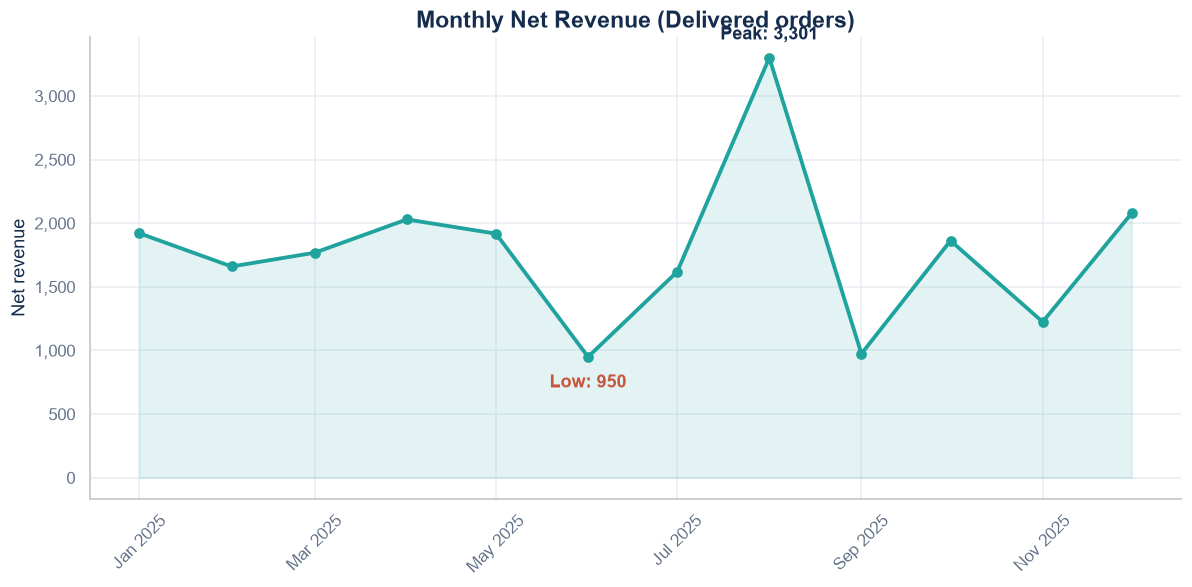

In [13]:
monthly = (delivered.groupby("month")
                    .agg(revenue=("revenue", "sum"), orders=("order_id", "nunique")))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(monthly.index, monthly["revenue"], marker="o", linewidth=2.5, color=TEAL)
ax.fill_between(monthly.index, monthly["revenue"], alpha=0.12, color=TEAL)

peak = monthly["revenue"].idxmax()
low = monthly["revenue"].idxmin()
ax.annotate(f"Peak: {monthly.loc[peak, 'revenue']:,.0f}", (peak, monthly.loc[peak, "revenue"]),
            textcoords="offset points", xytext=(0, 12), ha="center", color=NAVY, fontweight="bold")
ax.annotate(f"Low: {monthly.loc[low, 'revenue']:,.0f}", (low, monthly.loc[low, "revenue"]),
            textcoords="offset points", xytext=(0, -20), ha="center", color=RED, fontweight="bold")

ax.set_title("Monthly Net Revenue (Delivered orders)")
ax.set_xlabel("")
ax.set_ylabel("Net revenue")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 13. Customer loyalty

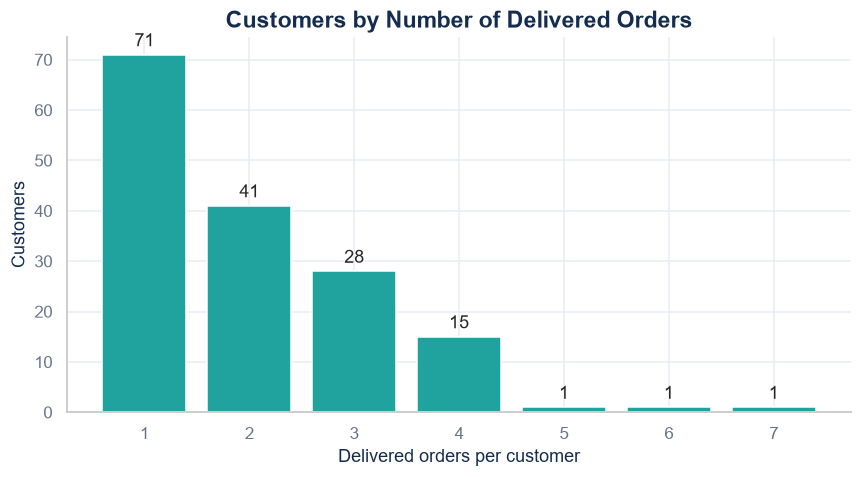

Top 10% of customers (15) generate 37.1% of net revenue.


In [14]:
dist = orders_per_customer.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dist.index.astype(str), dist.values, color=TEAL)
ax.bar_label(bars, padding=3)
ax.set_title("Customers by Number of Delivered Orders")
ax.set_xlabel("Delivered orders per customer")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

top = (delivered.groupby("customer_id")["revenue"].sum().sort_values(ascending=False))
print(f"Top 10% of customers ({max(1, int(len(top) * 0.1))}) generate {top.head(max(1, int(len(top) * 0.1))).sum() / top.sum():.1%} of net revenue.")

## 14. Key findings and recommendations
The text below is **generated from the data**, so the numbers always match the analysis above.

In [15]:
top_cat = cat.index[0]
top_cat_row = cat.iloc[0]
best_margin_cat = cat["margin"].idxmax()
ch = delivered.groupby("sales_channel")["revenue"].sum().sort_values(ascending=False)
seg = delivered.groupby("customer_segment")["revenue"].sum().sort_values(ascending=False)
ret_cat = loss_rates("category")["return_rate"].sort_values(ascending=False)
ret_ch = loss_rates("sales_channel")["return_rate"].sort_values(ascending=False)

if top_cat == best_margin_cat:
    margin_note = f"**{top_cat}** is both the largest and the highest-margin category, so it is the safest place to focus promotions and stock."
else:
    margin_note = f"**Protect margin, not only volume:** compare {top_cat} (largest) with {best_margin_cat} (best margin) before deciding where to spend on promotions."

if repeat_rate < 0.5:
    loyalty_note = "**Build repeat purchases** (follow-up offers, loyalty rewards), since most customers buy only once."
else:
    loyalty_note = "**Grow the loyal base:** most customers already return, so reward repeat buyers and look for ways to win back one-time buyers."

display(Markdown(f'''
### Key findings
- **Realised revenue is lower than it looks.** Of {gross_value:,.2f} in total order value, only **{net_revenue:,.2f}** came from delivered orders; **{lost_value / gross_value:.1%}** was lost to returns and cancellations.
- **{top_cat}** is the largest category with {top_cat_row['revenue']:,.2f} ({top_cat_row['share']:.1%} of net revenue). The highest-margin category is **{best_margin_cat}** at {cat.loc[best_margin_cat, 'margin']:.1%}.
- **{ch.index[0]}** is the strongest sales channel ({ch.iloc[0] / ch.sum():.1%} of net revenue). **{seg.index[0]}** customers contribute the most among segments ({seg.iloc[0] / seg.sum():.1%}).
- Return rate is highest for **{ret_cat.index[0]}** ({ret_cat.iloc[0]:.1%}) among categories and for **{ret_ch.index[0]}** ({ret_ch.iloc[0]:.1%}) among channels.
- Revenue peaked in **{peak:%B %Y}** ({monthly.loc[peak, 'revenue']:,.2f}) and was lowest in **{low:%B %Y}** ({monthly.loc[low, 'revenue']:,.2f}).
- **{repeat_rate:.1%}** of customers placed more than one delivered order.

### Recommendations
1. **Investigate returns in {ret_cat.index[0]}** (product descriptions, quality checks, packaging) because it has the highest return rate.
2. {margin_note}
3. {loyalty_note}
4. **Check cancellations by channel** to see whether stock-outs, payment problems or delivery delays are behind them.

### Limitations
- 500 orders from a single year, so seasonal conclusions are tentative.
- Cost is estimated; true profit may differ.
- Currency is not stated in the source data.
'''))


### Key findings
- **Realised revenue is lower than it looks.** Of 35,408.37 in total order value, only **21,310.28** came from delivered orders; **39.8%** was lost to returns and cancellations.
- **Furniture** is the largest category with 10,243.00 (48.1% of net revenue). The highest-margin category is **Stationery** at 65.6%.
- **Website** is the strongest sales channel (28.3% of net revenue). **Corporate** customers contribute the most among segments (40.0%).
- Return rate is highest for **Accessories** (26.5%) among categories and for **Retail Store** (27.6%) among channels.
- Revenue peaked in **August 2025** (3,300.68) and was lowest in **June 2025** (949.75).
- **55.1%** of customers placed more than one delivered order.

### Recommendations
1. **Investigate returns in Accessories** (product descriptions, quality checks, packaging) because it has the highest return rate.
2. **Protect margin, not only volume:** compare Furniture (largest) with Stationery (best margin) before deciding where to spend on promotions.
3. **Grow the loyal base:** most customers already return, so reward repeat buyers and look for ways to win back one-time buyers.
4. **Check cancellations by channel** to see whether stock-outs, payment problems or delivery delays are behind them.

### Limitations
- 500 orders from a single year, so seasonal conclusions are tentative.
- Cost is estimated; true profit may differ.
- Currency is not stated in the source data.
